In [1]:
import pandas as pd
import numpy as np
import os
import lightgbm as lgb
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ───────────────────────────────────────────────────────────────────
GENERATED_DIR = os.path.expanduser(
    "~/Desktop/dns-exfiltration-dataset/02_generated_dataset"
)
OUT_DIR = os.path.expanduser("~/Desktop/dns_results")
os.makedirs(OUT_DIR, exist_ok=True)

DROP_COLS = ["flow_id", "timestamp", "src_ip", "dst_ip",
             "dns_domain_name", "dns_top_level_domain",
             "dns_second_level_domain", "uni_gram_domain_name",
             "bi_gram_domain_name", "tri_gram_domain_name",
             "character_distribution", "ans_resource_record_type",
             "ans_resource_record_class"]

# ── 1. LOAD ALL GENERATED CSVs ───────────────────────────────────────────────
dfs = []

benign_path = os.path.join(GENERATED_DIR, "benign", "benign.csv")
df_b = pd.read_csv(benign_path)
df_b["source"] = "generated"
dfs.append(df_b)

malicious_dir = os.path.join(GENERATED_DIR, "malicious")
for tool in sorted(os.listdir(malicious_dir)):
    tool_dir = os.path.join(malicious_dir, tool)
    if not os.path.isdir(tool_dir):
        continue
    for f in os.listdir(tool_dir):
        if f.endswith(".csv"):
            df = pd.read_csv(os.path.join(tool_dir, f))
            df["source"] = "generated"
            df["tool"]   = tool
            dfs.append(df)
            print(f"  Loaded {tool}: {len(df)} rows")

df_all = pd.concat(dfs, ignore_index=True)
df_all["label"] = df_all["label"].apply(
    lambda x: 1 if str(x).strip().lower() == "malicious" else 0
)

drop = [c for c in DROP_COLS + ["source", "tool",
        "src_port", "dst_port"] if c in df_all.columns]
df_all = df_all.drop(columns=drop)

for col in df_all.columns:
    if col == "label":
        continue
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")
df_all = df_all.fillna(0)

print(f"\nTotal rows : {len(df_all)}")
print(f"Benign     : {(df_all['label']==0).sum()}")
print(f"Malicious  : {(df_all['label']==1).sum()}")
print(f"Features   : {df_all.shape[1] - 1}")

X = df_all.drop(columns=["label"]).values
y = df_all["label"].values
feature_names = df_all.drop(columns=["label"]).columns.tolist()

# ── 2. 70 / 15 / 15 SPLIT ───────────────────────────────────────────────────
# Generated data is ALL in here — no original pcap in test/val yet
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)
print(f"\nTrain : {len(y_train)}  |  Val : {len(y_val)}  |  Test : {len(y_test)}")

# ── 3. LIGHTGBM WITH EARLY STOPPING ─────────────────────────────────────────
params = dict(
    objective       = "binary",
    metric          = "auc",
    learning_rate   = 0.05,
    num_leaves      = 63,
    min_child_samples = 20,
    subsample       = 0.8,
    colsample_bytree= 0.8,
    reg_alpha       = 0.1,
    reg_lambda      = 0.1,
    random_state    = 42,
    n_jobs          = -1,
    verbose         = -1,
)

dtrain = lgb.Dataset(X_train, label=y_train, feature_name=feature_names)
dval   = lgb.Dataset(X_val,   label=y_val,   reference=dtrain)

print("\nTraining with early stopping (patience = 50 rounds)...")
callbacks = [lgb.early_stopping(50, verbose=True), lgb.log_evaluation(100)]
booster = lgb.train(
    params,
    dtrain,
    num_boost_round = 1000,
    valid_sets      = [dtrain, dval],
    valid_names     = ["train", "val"],
    callbacks       = callbacks,
)
print(f"Best iteration: {booster.best_iteration}")

# Test set evaluation
y_prob = booster.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int)
auc    = roc_auc_score(y_test, y_prob)
print(f"\n── Test Set Results ──")
print(f"AUC : {auc:.4f}")
print(classification_report(y_test, y_pred, target_names=["Benign","Malicious"]))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Benign","Malicious"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test Set — AUC {auc:.4f}", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix_holdout.png", dpi=150)
plt.close()

# ── 4. 5-FOLD CROSS-VALIDATION ───────────────────────────────────────────────
print("\n── 5-Fold Cross-Validation ──")
skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), 1):
    Xtr, Xva = X_train[tr_idx], X_train[va_idx]
    ytr, yva = y_train[tr_idx], y_train[va_idx]
    dtr = lgb.Dataset(Xtr, label=ytr, feature_name=feature_names)
    dva = lgb.Dataset(Xva, label=yva, reference=dtr)
    b = lgb.train(params, dtr, num_boost_round=booster.best_iteration,
                  valid_sets=[dva], valid_names=["val"],
                  callbacks=[lgb.log_evaluation(-1)])
    fold_auc = roc_auc_score(yva, b.predict(Xva))
    aucs.append(fold_auc)
    print(f"  Fold {fold}: AUC = {fold_auc:.4f}")
print(f"  Mean AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")

# ── 5. FEATURE IMPORTANCE HEATMAP ───────────────────────────────────────────
importance = booster.feature_importance(importance_type="gain")
importance_norm = importance / importance.sum() * 100  # percentage

fi_df = pd.DataFrame({
    "feature":    feature_names,
    "importance": importance_norm
}).sort_values("importance", ascending=False)

print(f"\nTop 10 features:\n{fi_df.head(10).to_string(index=False)}")

# Bar heatmap — color encodes importance %
fig, ax = plt.subplots(figsize=(10, max(6, len(feature_names) * 0.3)))
colors = plt.cm.RdYlGn(importance_norm[fi_df.index] / importance_norm.max())
bars = ax.barh(fi_df["feature"], fi_df["importance"],
               color=plt.cm.RdYlGn(fi_df["importance"] / fi_df["importance"].max()))
ax.set_xlabel("Importance (% of total gain)", fontsize=11)
ax.set_title("Feature Importance — DNS Exfiltration LightGBM\n"
             "(red = dominant, green = balanced)",
             fontsize=12, fontweight="bold")
ax.invert_yaxis()
for bar, val in zip(bars, fi_df["importance"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
            f"{val:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/feature_importance_heatmap.png", dpi=150, bbox_inches="tight")
plt.close()

# Save model
booster.save_model(f"{OUT_DIR}/dns_lgbm_phase2_v3.txt")
print(f"\nAll outputs saved to {OUT_DIR}")
print("Done ✓")

  Loaded cobaltstrike: 141207 rows
  Loaded dns2tcp: 65140 rows
  Loaded dnscat2: 144446 rows
  Loaded dnsexfiltrator: 58323 rows
  Loaded dnsexfiltrator_modified: 46596 rows
  Loaded dnspot: 26531 rows
  Loaded iodine: 130059 rows
  Loaded ozymandns: 61988 rows
  Loaded tcp_over_dns: 111247 rows

Total rows : 1583163
Benign     : 797626
Malicious  : 785537
Features   : 29

Train : 1108214  |  Val : 237474  |  Test : 237475

Training with early stopping (patience = 50 rounds)...
Training until validation scores don't improve for 50 rounds
[100]	train's auc: 1	val's auc: 1
[200]	train's auc: 1	val's auc: 1
[300]	train's auc: 1	val's auc: 1
[400]	train's auc: 1	val's auc: 1
Early stopping, best iteration is:
[359]	train's auc: 1	val's auc: 1
Best iteration: 359

── Test Set Results ──
AUC : 1.0000
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    119644
   Malicious       1.00      1.00      1.00    117831

    accuracy                 

In [1]:
import os, math, re, struct, warnings
from collections import defaultdict
import pandas as pd
import numpy as np
import dpkt
warnings.filterwarnings('ignore')

PCAP_ROOT = os.path.expanduser(
    "~/Desktop/dns-exfiltration-dataset/01_original_pcap_files"
)
OUT_DIR = os.path.expanduser("~/Desktop/dns_results/pcap_features")
os.makedirs(OUT_DIR, exist_ok=True)

MAX_BENIGN_FILES = 20   # cap so it finishes in minutes not hours

# ── helpers ──────────────────────────────────────────────────────────────────
def entropy(s):
    if not s: return 0.0
    freq = {}
    for c in s: freq[c] = freq.get(c, 0) + 1
    t = len(s)
    return -sum((v/t)*math.log2(v/t) for v in freq.values())

def max_run(s, kind):
    pats = {'numeric': r'\d+', 'alpha': r'[a-zA-Z]+',
            'consonant': r'[bcdfghjklmnpqrstvwxyzBCDFGHJKLMNPQRSTVWXYZ]+',
            'same': r'(.)\1+'}
    return max((len(m) for m in re.findall(pats[kind], s)), default=0)

def vc_ratio(s):
    v = sum(1 for c in s.lower() if c in 'aeiou')
    c = sum(1 for c in s.lower() if c.isalpha() and c not in 'aeiou')
    return v / c if c > 0 else 0.0

def parse_dns_name(data, offset):
    """Parse a DNS name from raw bytes."""
    labels = []
    visited = set()
    while offset < len(data):
        if offset in visited: break
        visited.add(offset)
        length = data[offset]
        if length == 0:
            offset += 1
            break
        elif (length & 0xC0) == 0xC0:  # pointer
            if offset + 1 >= len(data): break
            ptr = ((length & 0x3F) << 8) | data[offset + 1]
            offset += 2
            sub, _ = parse_dns_name(data, ptr)
            labels.append(sub)
            break
        else:
            offset += 1
            labels.append(data[offset:offset+length].decode('ascii', errors='replace'))
            offset += length
    return '.'.join(labels), offset

def extract_flows(pcap_path, label):
    flows = defaultdict(lambda: {'times':[], 'sizes':[], 'send':0, 'recv':0,
                                  'domain':'', 'ttls':[], 'rtypes':[], 'arecs':set()})
    try:
        with open(pcap_path, 'rb') as f:
            # Support both pcap and pcapng
            magic = f.read(4)
            f.seek(0)
            if magic == b'\x0a\x0d\x0d\x0a':  # pcapng
                reader = dpkt.pcapng.Reader(f)
            else:
                reader = dpkt.pcap.Reader(f)

            for ts, buf in reader:
                try:
                    eth = dpkt.ethernet.Ethernet(buf)
                    if not isinstance(eth.data, dpkt.ip.IP): continue
                    ip = eth.data
                    if not isinstance(ip.data, dpkt.udp.UDP): continue
                    udp = ip.data
                    if udp.dport != 53 and udp.sport != 53: continue

                    src = str(ip.src) if isinstance(ip.src, str) else '.'.join(str(b) for b in ip.src)
                    dst = str(ip.dst) if isinstance(ip.dst, str) else '.'.join(str(b) for b in ip.dst)

                    # Flow key: always client→server direction
                    if udp.dport == 53:
                        key = (src, udp.sport, dst, udp.dport)
                        direction = 'send'
                    else:
                        key = (dst, udp.dport, src, udp.sport)
                        direction = 'recv'

                    size = len(buf)
                    flows[key]['times'].append(ts)
                    flows[key]['sizes'].append(size)
                    flows[key][direction] += size

                    # Parse DNS
                    try:
                        dns = dpkt.dns.DNS(udp.data)
                        if dns.qd and not flows[key]['domain']:
                            flows[key]['domain'] = dns.qd[0].name
                        for rr in dns.an:
                            flows[key]['ttls'].append(rr.ttl)
                            flows[key]['rtypes'].append(rr.type)
                            if rr.type == dpkt.dns.DNS_A:
                                flows[key]['arecs'].add(rr.rdata)
                    except: pass
                except: continue
    except Exception as e:
        print(f"  Skipping {os.path.basename(pcap_path)}: {e}")
        return []

    rows = []
    for key, f in flows.items():
        if not f['times']: continue
        sizes = f['sizes']
        dur   = max(f['times'][-1] - f['times'][0], 0.001)
        n     = len(sizes)
        total = sum(sizes)
        mean_len = total / n
        std_len  = math.sqrt(sum((s-mean_len)**2 for s in sizes)/n)
        domain   = f['domain']
        parts    = domain.split('.')
        subdomain = '.'.join(parts[:-2]) if len(parts) > 2 else ''
        ttls     = f['ttls']
        rtypes   = f['rtypes']

        rows.append({
            'duration':                              dur,
            'total_bytes':                           total,
            'receiving_bytes':                       f['recv'],
            'sending_bytes':                         f['send'],
            'packets_rate':                          n / dur,
            'packets_len_rate':                      total / dur,
            'min_packets_len':                       min(sizes),
            'max_packets_len':                       max(sizes),
            'mean_packets_len':                      mean_len,
            'standard_deviation_packets_len':        std_len,
            'variance_packets_len':                  std_len**2,
            'coefficient_of_variation_packets_len':  std_len/mean_len if mean_len>0 else 0,
            'dns_domain_name_length':                len(domain),
            'dns_subdomain_name_length':             len(subdomain),
            'numerical_percentage':                  sum(c.isdigit() for c in domain)/len(domain) if domain else 0,
            'character_entropy':                     entropy(domain),
            'max_continuous_numeric_len':            max_run(domain,'numeric'),
            'max_continuous_alphabet_len':           max_run(domain,'alpha'),
            'max_continuous_consonants_len':         max_run(domain,'consonant'),
            'max_continuous_same_alphabet_len':      max_run(domain,'same'),
            'vowels_consonant_ratio':                vc_ratio(domain),
            'conv_freq_vowels_consonants':           sum(1 for c in domain.lower() if c.isalpha())/len(domain) if domain else 0,
            'distinct_ttl_values':                   len(set(ttls)),
            'ttl_values_min':                        min(ttls) if ttls else 0,
            'ttl_values_max':                        max(ttls) if ttls else 0,
            'ttl_values_mean':                       sum(ttls)/len(ttls) if ttls else 0,
            'ttl_values_mode':                       max(set(ttls), key=ttls.count) if ttls else 0,
            'ttl_values_median':                     sorted(ttls)[len(ttls)//2] if ttls else 0,
            'distinct_A_records':                    len(f['arecs']),
            'label':                                 label,
        })
    return rows

# ── MALICIOUS ─────────────────────────────────────────────────────────────────
print("Processing malicious...")
mal_rows = []
mal_root = os.path.join(PCAP_ROOT, "malicious")
for tool in sorted(os.listdir(mal_root)):
    tool_dir = os.path.join(mal_root, tool)
    if not os.path.isdir(tool_dir): continue
    tool_rows = []
    for f in sorted(os.listdir(tool_dir)):
        if not (f.endswith('.pcap') or f.endswith('.pcapng')): continue
        rows = extract_flows(os.path.join(tool_dir, f), label=1)
        tool_rows.extend(rows)
    mal_rows.extend(tool_rows)
    print(f"  {tool}: {len(tool_rows)} flows")

# ── BENIGN (capped) ───────────────────────────────────────────────────────────
print(f"\nProcessing benign (max {MAX_BENIGN_FILES} files)...")
ben_rows = []
ben_root = os.path.join(PCAP_ROOT, "benign")
all_ben_files = []
for root, dirs, files in os.walk(ben_root):
    for f in files:
        if f.endswith('.pcap') or f.endswith('.pcapng'):
            all_ben_files.append(os.path.join(root, f))

all_ben_files = sorted(all_ben_files)[:MAX_BENIGN_FILES]
for path in all_ben_files:
    rows = extract_flows(path, label=0)
    ben_rows.extend(rows)
    print(f"  {os.path.basename(path)}: {len(rows)} flows")

# ── SAVE ──────────────────────────────────────────────────────────────────────
df_mal = pd.DataFrame(mal_rows)
df_ben = pd.DataFrame(ben_rows)
df_all = pd.concat([df_mal, df_ben], ignore_index=True)

df_all.to_csv(f"{OUT_DIR}/original_all.csv", index=False)

print(f"\nDone.")
print(f"Malicious : {len(df_mal)} flows")
print(f"Benign    : {len(df_ben)} flows")
print(f"Total     : {len(df_all)} flows")

Processing malicious...
  cobaltstrike: 76724 flows
  dns2tcp: 4 flows
  dnscat2: 8 flows
  dnsexfiltrator: 448 flows
  dnsexfiltrator_modified: 583 flows
  dnspot: 17197 flows
  iodine: 21 flows
  ozymandns: 40037 flows
  tcp_over_dns: 2 flows

Processing benign (max 20 files)...
  normal_00000_20230805150331.pcap: 7203 flows
  normal_00001_20230805152732.pcap: 7535 flows
  normal_00002_20230805155315.pcap: 7865 flows
  normal_00003_20230805162300.pcap: 7737 flows
  normal_00004_20230805165638.pcap: 7904 flows
  normal_00005_20230805173251.pcap: 5513 flows
  normal_00006_20230805193455.pcap: 5158 flows
  normal_00007_20230805194417.pcap: 5660 flows
  normal_00008_20230805195347.pcap: 5661 flows
  normal_00009_20230805200318.pcap: 5317 flows
  normal_00010_20230805201245.pcap: 5012 flows
  normal_00011_20230805202204.pcap: 6169 flows
  normal_00012_20230805204207.pcap: 8067 flows
  normal_00013_20230805204920.pcap: 5785 flows
  normal_00014_20230805205702.pcap: 5584 flows
  normal_0001

In [ ]:
import os, math, re, warnings
from collections import defaultdict
import pandas as pd
import numpy as np
import dpkt
warnings.filterwarnings('ignore')

PCAP_ROOT = os.path.expanduser(
    "~/Desktop/dns-exfiltration-dataset/01_original_pcap_files"
)
OUT_DIR = os.path.expanduser("~/Desktop/dns_results/pcap_features")
os.makedirs(OUT_DIR, exist_ok=True)

def entropy(s):
    if not s: return 0.0
    freq = {}
    for c in s: freq[c] = freq.get(c, 0) + 1
    t = len(s)
    return -sum((v/t)*math.log2(v/t) for v in freq.values())

def max_run(s, kind):
    pats = {'numeric': r'\d+', 'alpha': r'[a-zA-Z]+',
            'consonant': r'[bcdfghjklmnpqrstvwxyzBCDFGHJKLMNPQRSTVWXYZ]+',
            'same': r'(.)\1+'}
    return max((len(m) for m in re.findall(pats[kind], s)), default=0)

def vc_ratio(s):
    v = sum(1 for c in s.lower() if c in 'aeiou')
    c = sum(1 for c in s.lower() if c.isalpha() and c not in 'aeiou')
    return v / c if c > 0 else 0.0

def make_row(key, f, label):
    sizes    = f['sizes']
    dur      = max(f['times'][-1] - f['times'][0], 0.001)
    n        = len(sizes)
    total    = sum(sizes)
    mean_len = total / n
    std_len  = math.sqrt(sum((s-mean_len)**2 for s in sizes)/n)
    domain   = f['domain']
    parts    = domain.split('.')
    subdomain = '.'.join(parts[:-2]) if len(parts) > 2 else ''
    ttls     = f['ttls']
    return {
        'duration':                              dur,
        'total_bytes':                           total,
        'receiving_bytes':                       f['recv'],
        'sending_bytes':                         f['send'],
        'packets_rate':                          n / dur,
        'packets_len_rate':                      total / dur,
        'min_packets_len':                       min(sizes),
        'max_packets_len':                       max(sizes),
        'mean_packets_len':                      mean_len,
        'standard_deviation_packets_len':        std_len,
        'variance_packets_len':                  std_len**2,
        'coefficient_of_variation_packets_len':  std_len/mean_len if mean_len>0 else 0,
        'dns_domain_name_length':                len(domain),
        'dns_subdomain_name_length':             len(subdomain),
        'numerical_percentage':                  sum(c.isdigit() for c in domain)/len(domain) if domain else 0,
        'character_entropy':                     entropy(domain),
        'max_continuous_numeric_len':            max_run(domain,'numeric'),
        'max_continuous_alphabet_len':           max_run(domain,'alpha'),
        'max_continuous_consonants_len':         max_run(domain,'consonant'),
        'max_continuous_same_alphabet_len':      max_run(domain,'same'),
        'vowels_consonant_ratio':                vc_ratio(domain),
        'conv_freq_vowels_consonants':           sum(1 for c in domain.lower() if c.isalpha())/len(domain) if domain else 0,
        'distinct_ttl_values':                   len(set(ttls)),
        'ttl_values_min':                        min(ttls) if ttls else 0,
        'ttl_values_max':                        max(ttls) if ttls else 0,
        'ttl_values_mean':                       sum(ttls)/len(ttls) if ttls else 0,
        'ttl_values_mode':                       max(set(ttls), key=ttls.count) if ttls else 0,
        'ttl_values_median':                     sorted(ttls)[len(ttls)//2] if ttls else 0,
        'distinct_A_records':                    len(f['arecs']),
        'label':                                 label,
    }

def extract_flows(pcap_path, label):
    flows = defaultdict(lambda: {'times':[], 'sizes':[], 'send':0, 'recv':0,
                                  'domain':'', 'ttls':[], 'rtypes':[], 'arecs':set()})
    try:
        with open(pcap_path, 'rb') as f:
            magic = f.read(4); f.seek(0)
            reader = dpkt.pcapng.Reader(f) if magic == b'\x0a\x0d\x0d\x0a' else dpkt.pcap.Reader(f)
            for ts, buf in reader:
                try:
                    eth = dpkt.ethernet.Ethernet(buf)
                    ip = eth.data
                    if not isinstance(ip, dpkt.ip.IP): continue

                    # Support both UDP and TCP port 53
                    transport = ip.data
                    is_udp = isinstance(transport, dpkt.udp.UDP)
                    is_tcp = isinstance(transport, dpkt.tcp.TCP)
                    if not (is_udp or is_tcp): continue

                    sport = transport.sport
                    dport = transport.dport
                    if dport != 53 and sport != 53: continue

                    src = '.'.join(str(b) for b in ip.src)
                    dst = '.'.join(str(b) for b in ip.dst)

                    if dport == 53:
                        key = (src, sport, dst, dport)
                        direction = 'send'
                    else:
                        key = (dst, dport, src, sport)
                        direction = 'recv'

                    size = len(buf)
                    flows[key]['times'].append(ts)
                    flows[key]['sizes'].append(size)
                    flows[key][direction] += size

                    # Parse DNS payload
                    try:
                        payload = transport.data
                        # TCP DNS has a 2-byte length prefix
                        if is_tcp and len(payload) > 2:
                            payload = payload[2:]
                        dns = dpkt.dns.DNS(payload)
                        if dns.qd and not flows[key]['domain']:
                            flows[key]['domain'] = dns.qd[0].name
                        for rr in dns.an:
                            flows[key]['ttls'].append(rr.ttl)
                            flows[key]['rtypes'].append(rr.type)
                            if rr.type == dpkt.dns.DNS_A:
                                try: flows[key]['arecs'].add(rr.rdata)
                                except: pass
                    except: pass
                except: continue
    except Exception as e:
        print(f"  Skipping {os.path.basename(pcap_path)}: {e}")
        return []

    return [make_row(k, f, label) for k, f in flows.items() if f['times']]

# ── MALICIOUS ─────────────────────────────────────────────────────────────────
print("Processing malicious (UDP + TCP)...")
mal_rows = []
mal_root = os.path.join(PCAP_ROOT, "malicious")
for tool in sorted(os.listdir(mal_root)):
    tool_dir = os.path.join(mal_root, tool)
    if not os.path.isdir(tool_dir): continue
    tool_rows = []
    for f in sorted(os.listdir(tool_dir)):
        if not (f.endswith('.pcap') or f.endswith('.pcapng')): continue
        rows = extract_flows(os.path.join(tool_dir, f), label=1)
        tool_rows.extend(rows)
    mal_rows.extend(tool_rows)
    print(f"  {tool}: {len(tool_rows)} flows")

# ── BENIGN (all files) ────────────────────────────────────────────────────────
print(f"\nProcessing benign (all files)...")
ben_rows = []
ben_root = os.path.join(PCAP_ROOT, "benign")
all_ben_files = []
for root, dirs, files in os.walk(ben_root):
    for f in sorted(files):
        if f.endswith('.pcap') or f.endswith('.pcapng'):
            all_ben_files.append(os.path.join(root, f))

for path in sorted(all_ben_files):
    rows = extract_flows(path, label=0)
    ben_rows.extend(rows)
    print(f"  {os.path.basename(path)}: {len(rows)} flows")

# ── SAVE ──────────────────────────────────────────────────────────────────────
df_mal = pd.DataFrame(mal_rows)
df_ben = pd.DataFrame(ben_rows)
df_all = pd.concat([df_mal, df_ben], ignore_index=True)
df_all.to_csv(f"{OUT_DIR}/original_all.csv", index=False)

print(f"\nDone.")
print(f"Malicious : {len(df_mal)} flows")
print(f"Benign    : {len(df_ben)} flows")
print(f"Total     : {len(df_all)} flows")

Processing malicious (UDP + TCP)...
  cobaltstrike: 76724 flows
  dns2tcp: 4 flows
  dnscat2: 8 flows
  dnsexfiltrator: 448 flows
  dnsexfiltrator_modified: 583 flows
  dnspot: 17197 flows
  iodine: 21 flows
  ozymandns: 40037 flows
  tcp_over_dns: 2 flows

Processing benign (all files)...
  normal_00000_20230805150331.pcap: 7203 flows
  normal_00001_20230805152732.pcap: 7535 flows
  normal_00002_20230805155315.pcap: 7865 flows
  normal_00003_20230805162300.pcap: 7737 flows
  normal_00004_20230805165638.pcap: 7904 flows
  normal_00005_20230805173251.pcap: 5513 flows
  normal_00006_20230805193455.pcap: 5158 flows
  normal_00007_20230805194417.pcap: 5660 flows
  normal_00008_20230805195347.pcap: 5661 flows
  normal_00009_20230805200318.pcap: 5317 flows
  normal_00010_20230805201245.pcap: 5012 flows
  normal_00011_20230805202204.pcap: 6169 flows
  normal_00012_20230805204207.pcap: 8067 flows
  normal_00013_20230805204920.pcap: 5785 flows
  normal_00014_20230805205702.pcap: 5584 flows
  no

In [1]:
import pandas as pd, os
path = os.path.expanduser("~/Desktop/dns_results/pcap_features/original_all.csv")
df = pd.read_csv(path)
print(df.shape)
print(df['label'].value_counts())

(258934, 30)
1    135024
0    123910
Name: label, dtype: int64


In [1]:
import pandas as pd
import numpy as np
import os
import lightgbm as lgb
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

GENERATED_DIR = os.path.expanduser("~/Desktop/dns-exfiltration-dataset/02_generated_dataset")
ORIG_CSV      = os.path.expanduser("~/Desktop/dns_results/pcap_features/original_all.csv")
OUT_DIR       = os.path.expanduser("~/Desktop/dns_results")
os.makedirs(OUT_DIR, exist_ok=True)

DROP_COLS = ["flow_id","timestamp","src_ip","dst_ip","src_port","dst_port",
             "dns_domain_name","dns_top_level_domain","dns_second_level_domain",
             "uni_gram_domain_name","bi_gram_domain_name","tri_gram_domain_name",
             "character_distribution","ans_resource_record_type","ans_resource_record_class",
             "source","tool"]

# ── Load generated data (train only) ─────────────────────────────────────────
print("Loading generated CSVs...")
dfs = []
benign_path = os.path.join(GENERATED_DIR, "benign", "benign.csv")
df_b = pd.read_csv(benign_path); df_b["source"] = "generated"; dfs.append(df_b)
for tool in sorted(os.listdir(os.path.join(GENERATED_DIR, "malicious"))):
    tool_dir = os.path.join(GENERATED_DIR, "malicious", tool)
    if not os.path.isdir(tool_dir): continue
    for f in os.listdir(tool_dir):
        if f.endswith(".csv"):
            df = pd.read_csv(os.path.join(tool_dir, f))
            df["source"] = "generated"; df["tool"] = tool; dfs.append(df)
df_gen = pd.concat(dfs, ignore_index=True)
df_gen["label"] = df_gen["label"].apply(lambda x: 1 if str(x).strip().lower()=="malicious" else 0)
drop_gen = [c for c in DROP_COLS if c in df_gen.columns]
df_gen = df_gen.drop(columns=drop_gen)
for col in df_gen.columns:
    if col != "label": df_gen[col] = pd.to_numeric(df_gen[col], errors="coerce")
df_gen = df_gen.fillna(0)
print(f"Generated: {len(df_gen)} rows | label 0:{(df_gen.label==0).sum()} 1:{(df_gen.label==1).sum()}")

# ── Load original pcap features ───────────────────────────────────────────────
print("Loading original pcap CSV...")
df_orig = pd.read_csv(ORIG_CSV)
drop_orig = [c for c in DROP_COLS if c in df_orig.columns]
df_orig = df_orig.drop(columns=drop_orig)
for col in df_orig.columns:
    if col != "label": df_orig[col] = pd.to_numeric(df_orig[col], errors="coerce")
df_orig = df_orig.fillna(0)
print(f"Original : {len(df_orig)} rows | label 0:{(df_orig.label==0).sum()} 1:{(df_orig.label==1).sum()}")

# ── Split original 70/15/15 ───────────────────────────────────────────────────
X_o = df_orig.drop(columns=["label"]).values
y_o = df_orig["label"].values
feature_names = df_orig.drop(columns=["label"]).columns.tolist()

X_o_train, X_o_temp, y_o_train, y_o_temp = train_test_split(X_o, y_o, test_size=0.40, stratify=y_o, random_state=5)
X_o_val,   X_o_test, y_o_val,   y_o_test = train_test_split(X_o_temp, y_o_temp, test_size=0.50, stratify=y_o_temp, random_state=5)

# ── Combine: generated goes to train only ─────────────────────────────────────
X_gen = df_gen.drop(columns=["label"]).values
y_gen = df_gen["label"].values

# Align columns (generated may have extra cols)
gen_cols = df_gen.drop(columns=["label"]).columns.tolist()
orig_cols = feature_names
common = [c for c in orig_cols if c in gen_cols]
missing = [c for c in orig_cols if c not in gen_cols]
print(f"Common features: {len(common)} | Missing in generated: {missing}")

df_gen_aligned = df_gen[common + ["label"]]
X_gen_a = df_gen_aligned.drop(columns=["label"]).values
y_gen_a = df_gen_aligned["label"].values

# Use only common features for original too
df_orig_common = df_orig[common + ["label"]]
X_o = df_orig_common.drop(columns=["label"]).values
y_o = df_orig_common["label"].values
X_o_train, X_o_temp, y_o_train, y_o_temp = train_test_split(X_o, y_o, test_size=0.40, stratify=y_o, random_state=5)
X_o_val,   X_o_test, y_o_val,   y_o_test = train_test_split(X_o_temp, y_o_temp, test_size=0.50, stratify=y_o_temp, random_state=5)

X_train = np.vstack([X_gen_a, X_o_train])
y_train = np.concatenate([y_gen_a, y_o_train])
X_val   = X_o_val;  y_val  = y_o_val
X_test  = X_o_test; y_test = y_o_test

print(f"\nTrain : {len(X_train)} (gen={len(X_gen_a)} + orig={len(X_o_train)})")
print(f"Val   : {len(X_val)}")
print(f"Test  : {len(X_test)}")

# ── Train LightGBM ────────────────────────────────────────────────────────────
params = dict(
    objective="binary", metric="auc", learning_rate=0.05, num_leaves=63,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1, random_state=5, n_jobs=-1, verbose=-1,
)
dtrain = lgb.Dataset(X_train, label=y_train, feature_name=common)
dval   = lgb.Dataset(X_val,   label=y_val,   reference=dtrain)
callbacks = [lgb.early_stopping(50, verbose=True), lgb.log_evaluation(100)]
booster = lgb.train(params, dtrain, num_boost_round=1000,
                    valid_sets=[dval], valid_names=["val"],
                    callbacks=callbacks)

booster.save_model(f"{OUT_DIR}/dns_lgbm_final.txt")

# ── Evaluate on test (original pcap only) ────────────────────────────────────
y_prob = booster.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int)
auc    = roc_auc_score(y_test, y_prob)
print(f"\nTest AUC : {auc:.4f}")
print(classification_report(y_test, y_pred, target_names=["Benign","Malicious"]))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm, display_labels=["Benign","Malicious"]).plot(ax=ax, colorbar=False)
ax.set_title(f"DNS Final Model — Test AUC {auc:.4f}")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix_final.png", dpi=150)
plt.close()
print("Confusion matrix saved.")

# ── Feature importance heatmap ────────────────────────────────────────────────
imp = booster.feature_importance(importance_type="gain")
imp_pct = imp / imp.sum() * 100
fi = pd.DataFrame({"feature": common, "importance_pct": imp_pct}).sort_values("importance_pct", ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(fi.set_index("feature")[["importance_pct"]].T, annot=True, fmt=".1f",
            cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("Feature Importance (% of total gain)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/feature_importance_final.png", dpi=150)
plt.close()
print("Feature importance heatmap saved.")
print("\nAll done.")

Loading generated CSVs...
Generated: 1583163 rows | label 0:797626 1:785537
Loading original pcap CSV...
Original : 258934 rows | label 0:123910 1:135024
Common features: 29 | Missing in generated: []

Train : 1738523 (gen=1583163 + orig=155360)
Val   : 51787
Test  : 51787
Training until validation scores don't improve for 50 rounds
[100]	val's auc: 1
Early stopping, best iteration is:
[138]	val's auc: 1

Test AUC : 1.0000
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     24782
   Malicious       1.00      1.00      1.00     27005

    accuracy                           1.00     51787
   macro avg       1.00      1.00      1.00     51787
weighted avg       1.00      1.00      1.00     51787

Confusion matrix saved.
Feature importance heatmap saved.

All done.


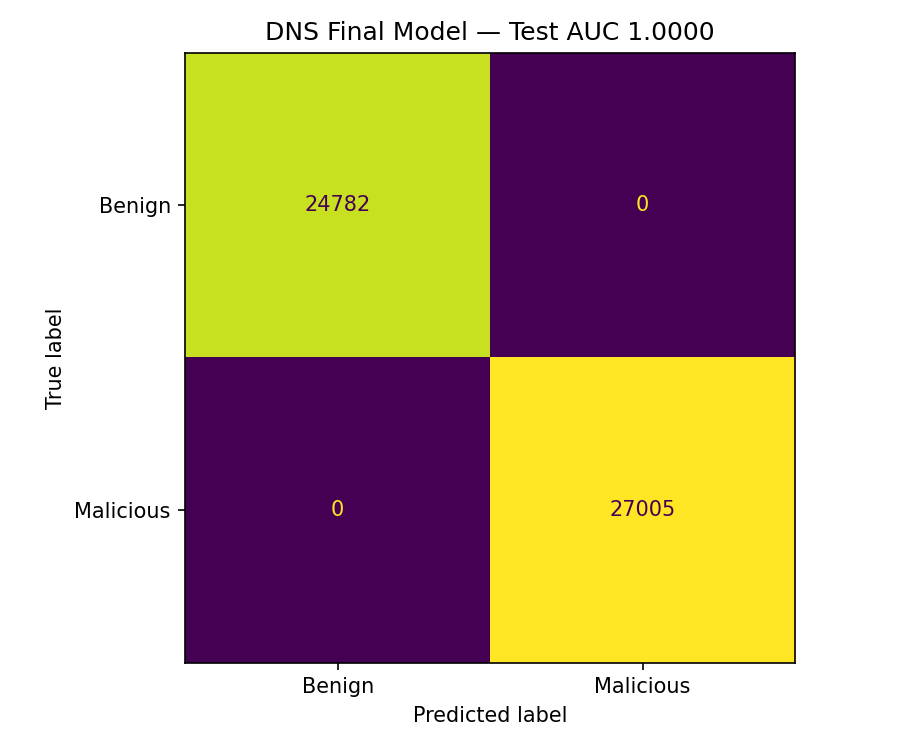

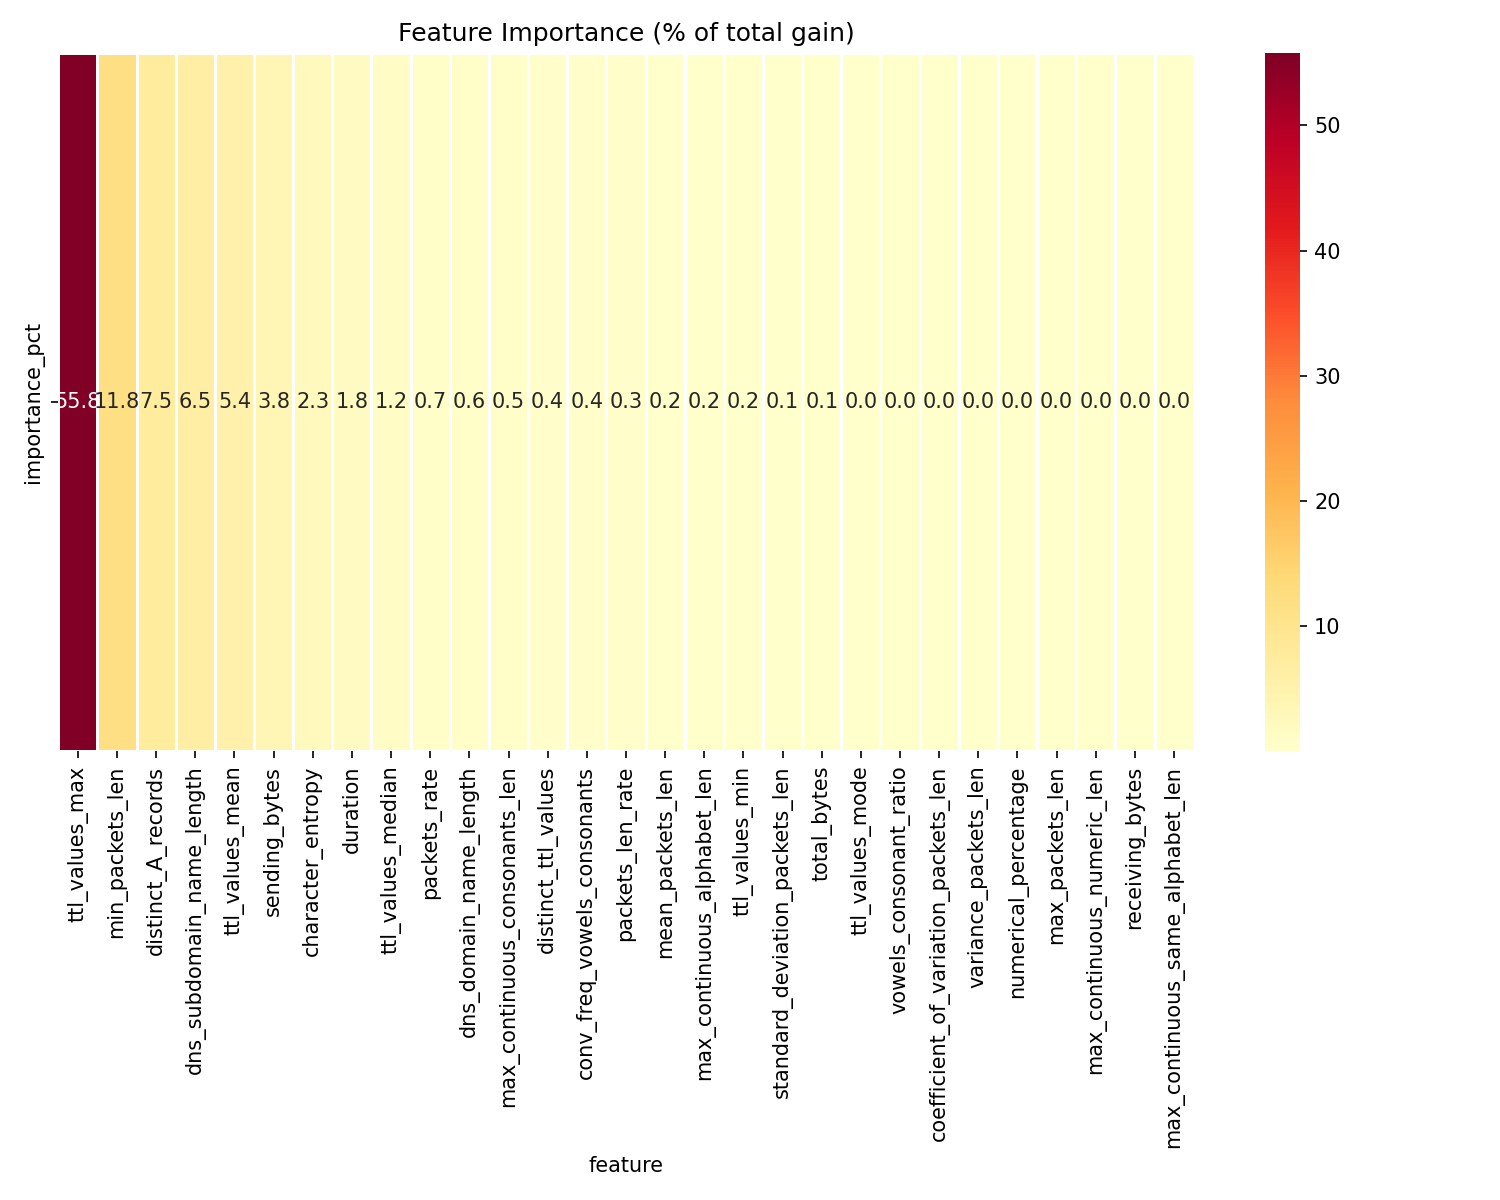

In [2]:
from IPython.display import Image, display
display(Image(f"{OUT_DIR}/confusion_matrix_final.png"))
display(Image(f"{OUT_DIR}/feature_importance_final.png"))

In [4]:
import shutil, os
out = os.path.expanduser("~/Desktop/dns_results")
shutil.make_archive(os.path.expanduser("~/Desktop/dns_final_model"), 'zip', out)
print("Done:", os.path.expanduser("~/Desktop/dns_final_model.zip"))

Done: /Users/kamal/Desktop/dns_final_model.zip


In [5]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Original pcap only for cross-validation (generated stays train-only)
X_orig = df_orig[common].values
y_orig = df_orig["label"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_aucs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_orig, y_orig)):
    X_fold_test  = X_orig[test_idx]
    y_fold_test  = y_orig[test_idx]

    # Train = generated + this fold's train portion of original
    X_fold_train = np.vstack([X_gen_a, X_orig[train_idx]])
    y_fold_train = np.concatenate([y_gen_a, y_orig[train_idx]])

    dtrain_cv = lgb.Dataset(X_fold_train, label=y_fold_train, feature_name=common)
    dval_cv   = lgb.Dataset(X_fold_test,  label=y_fold_test,  reference=dtrain_cv)

    cb = [lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
    bst_cv = lgb.train(params, dtrain_cv, num_boost_round=1000,
                       valid_sets=[dval_cv], valid_names=["val"],
                       callbacks=cb)

    y_prob_cv = bst_cv.predict(X_fold_test)
    auc_cv    = roc_auc_score(y_fold_test, y_prob_cv)
    cv_aucs.append(auc_cv)
    print(f"  Fold {fold+1}: AUC = {auc_cv:.4f}  (best iter={bst_cv.best_iteration})")

print(f"\nMean AUC : {np.mean(cv_aucs):.4f}")
print(f"Std AUC  : {np.std(cv_aucs):.4f}")

  Fold 1: AUC = 1.0000  (best iter=78)
  Fold 2: AUC = 1.0000  (best iter=63)
  Fold 3: AUC = 1.0000  (best iter=49)
  Fold 4: AUC = 1.0000  (best iter=62)
  Fold 5: AUC = 1.0000  (best iter=94)

Mean AUC : 1.0000
Std AUC  : 0.0000


import shutil, os

final_dir = os.path.expanduser("~/Desktop/dns_exfil_final")
os.makedirs(final_dir, exist_ok=True)

src = os.path.expanduser("~/Desktop/dns_results")
for f in ["dns_lgbm_final.txt", "confusion_matrix_final.png",
          "feature_importance_final.png"]:
    shutil.copy(os.path.join(src, f), final_dir)

shutil.make_archive(final_dir, 'zip', final_dir)
print("Ready:", final_dir + ".zip")

In [6]:
import shutil, os

final_dir = os.path.expanduser("~/Desktop/dns_exfil_final")
os.makedirs(final_dir, exist_ok=True)

src = os.path.expanduser("~/Desktop/dns_results")
for f in ["dns_lgbm_final.txt", "confusion_matrix_final.png",
          "feature_importance_final.png"]:
    shutil.copy(os.path.join(src, f), final_dir)

shutil.make_archive(final_dir, 'zip', final_dir)
print("Ready:", final_dir + ".zip")

Ready: /Users/kamal/Desktop/dns_exfil_final.zip


In [ ]:
# Remove ALL ttl features and retrain
ttl_features = [c for c in common if 'ttl' in c.lower()]
no_ttl = [c for c in common if 'ttl' not in c.lower()]

print(f"Dropping TTL features: {ttl_features}")
print(f"Remaining features: {len(no_ttl)}")

X_gen_no_ttl  = df_gen[no_ttl].values
X_orig_no_ttl = df_orig[no_ttl].values

X_o_train, X_o_temp, y_o_train, y_o_temp = train_test_split(
    X_orig_no_ttl, y_orig, test_size=0.30, stratify=y_orig, random_state=42)
X_o_val, X_o_test, y_o_val, y_o_test = train_test_split(
    X_o_temp, y_o_temp, test_size=0.50, stratify=y_o_temp, random_state=42)
X_train_nt = np.vstack([X_gen_no_ttl, X_o_train])
y_train_nt = np.concatenate([y_gen_a, y_o_train])

dtrain_nt = lgb.Dataset(X_train_nt, label=y_train_nt, feature_name=no_ttl)
dval_nt   = lgb.Dataset(X_o_val,    label=y_o_val,    reference=dtrain_nt)

cb = [lgb.early_stopping(50, verbose=True), lgb.log_evaluation(100)]
bst_nt = lgb.train(params, dtrain_nt, num_boost_round=1000,
                   valid_sets=[dtrain_nt, dval_nt], valid_names=["train","val"],
                   callbacks=cb)

y_prob_nt = bst_nt.predict(X_o_test)
auc_nt    = roc_auc_score(y_o_test, y_prob_nt)
print(f"\nAUC without TTL features: {auc_nt:.4f}")
print(f"AUC with TTL features:    1.0000")

Dropping TTL features: ['distinct_ttl_values', 'ttl_values_min', 'ttl_values_max', 'ttl_values_mean', 'ttl_values_mode', 'ttl_values_median']
Remaining features: 23
Training until validation scores don't improve for 50 rounds
[100]	train's auc: 1	val's auc: 1
Early stopping, best iteration is:
[80]	train's auc: 0.999999	val's auc: 1

AUC without TTL features: 1.0000
AUC with TTL features:    1.0000


In [8]:
import pandas as pd

imp = booster.feature_importance(importance_type="gain")
imp_pct = imp / imp.sum() * 100
fi = pd.DataFrame({"feature": common, "importance_pct": imp_pct})\
       .sort_values("importance_pct", ascending=False)

for _, row in fi.iterrows():
    print(f"  {row['feature']:<45} {row['importance_pct']:>6.2f}%")

  ttl_values_max                                 55.61%
  min_packets_len                                 8.59%
  dns_subdomain_name_length                       8.02%
  distinct_A_records                              7.39%
  ttl_values_mean                                 6.16%
  sending_bytes                                   5.26%
  dns_domain_name_length                          2.48%
  packets_rate                                    1.79%
  ttl_values_median                               0.90%
  character_entropy                               0.84%
  duration                                        0.72%
  max_continuous_consonants_len                   0.64%
  distinct_ttl_values                             0.36%
  mean_packets_len                                0.24%
  conv_freq_vowels_consonants                     0.24%
  max_continuous_alphabet_len                     0.16%
  ttl_values_min                                  0.14%
  receiving_bytes                               